# Lab 01: Sentiment Analysis Using Traditional Machine Learning

**Dataset:** UCI Sentiment Labelled Sentences (Amazon, IMDb, Yelp)
**Pipeline:** Load → Preprocess → Explore → Split → Bag-of-Words → Train → Evaluate → Predict

In [1]:
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from collections import Counter
from nltk.corpus import stopwords
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix)

nltk.download("stopwords")
sns.set_theme(style="whitegrid")

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\rajap\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


## 1. Load the dataset

In [2]:
files = {
    "amazon": "../data/amazon_cells_labelled.txt",
    "imdb": "../data/imdb_labelled.txt",
    "yelp": "../data/yelp_labelled.txt",
}

frames = []
for source, path in files.items():
    part = pd.read_csv(path, sep="\t", header=None, names=["text", "label"], quoting=3)
    part["source"] = source
    frames.append(part)

df = pd.concat(frames, ignore_index=True)
print(df.shape)
df.head()

(3000, 3)


,text,label,source
0,So there is no way for me to plug it in here i...,0,amazon
1,"Good case, Excellent value.",1,amazon
2,Great for the jawbone.,1,amazon
3,Tied to charger for conversations lasting more...,0,amazon
4,The mic is great.,1,amazon


<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   text    3000 non-null   str  
 1   label   3000 non-null   int64
 2   source  3000 non-null   str  
dtypes: int64(1), str(2)
memory usage: 70.4 KB
None
label
0    1500
1    1500
Name: count, dtype: int64


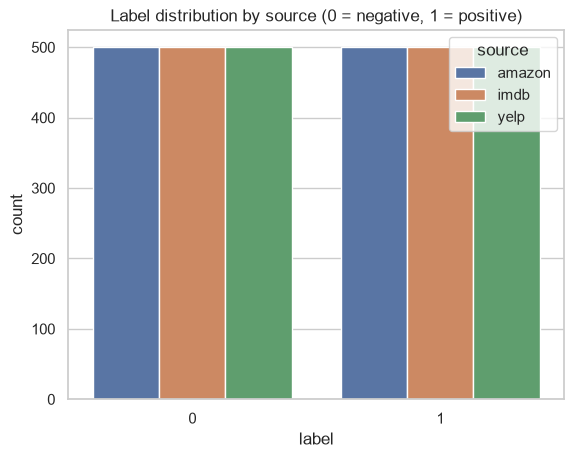

In [3]:
print(df.info())
print(df["label"].value_counts())

sns.countplot(data=df, x="label", hue="source")
plt.title("Label distribution by source (0 = negative, 1 = positive)")
plt.show()

## 2. Text preprocessing

In [4]:
def clean_text(text):
    text = text.lower()                          # lowercase
    text = re.sub(r"[^a-z\s]", " ", text)        # remove punctuation, digits, symbols
    text = re.sub(r"\s+", " ", text).strip()     # remove extra whitespace
    return text

df["clean_text"] = df["text"].apply(clean_text)
df[["text", "clean_text"]].sample(8, random_state=42)

,text,clean_text
1801,Avoid at ALL costs!,avoid at all costs
1190,"Garbo, who showed right off the bat that her t...",garbo who showed right off the bat that her ta...
1817,You will leave the theater wanting to go out a...,you will leave the theater wanting to go out a...
251,O my gosh the best phone I have ever had.,o my gosh the best phone i have ever had
2505,I would not recommend this place.,i would not recommend this place
1117,Then scene where they debated whether or not t...,then scene where they debated whether or not t...
1411,Her role was played well.,her role was played well
2113,"Nice, spicy and tender.",nice spicy and tender


In [5]:
for i in df.sample(3, random_state=7).index:
    print("ORIGINAL :", df.loc[i, "text"])
    print("CLEANED  :", df.loc[i, "clean_text"])
    print("-" * 60)

ORIGINAL : In a most wonderful location lies a story of contrast.  
CLEANED  : in a most wonderful location lies a story of contrast
------------------------------------------------------------
ORIGINAL : Poor service, the waiter made me feel like I was stupid every time he came to the table.
CLEANED  : poor service the waiter made me feel like i was stupid every time he came to the table
------------------------------------------------------------
ORIGINAL : Great Product.
CLEANED  : great product
------------------------------------------------------------


## 3. Explore the text data

In [6]:
print("POSITIVE EXAMPLES")
for t in df[df["label"] == 1]["text"].head(5):
    print("  +", t)

print("\nNEGATIVE EXAMPLES")
for t in df[df["label"] == 0]["text"].head(5):
    print("  -", t)

POSITIVE EXAMPLES
  + Good case, Excellent value.
  + Great for the jawbone.
  + The mic is great.
  + If you are Razr owner...you must have this!
  + And the sound quality is great.

NEGATIVE EXAMPLES
  - So there is no way for me to plug it in here in the US unless I go by a converter.
  - Tied to charger for conversations lasting more than 45 minutes.MAJOR PROBLEMS!!
  - I have to jiggle the plug to get it to line up right to get decent volume.
  - If you have several dozen or several hundred contacts, then imagine the fun of sending each of them one by one.
  - Needless to say, I wasted my money.


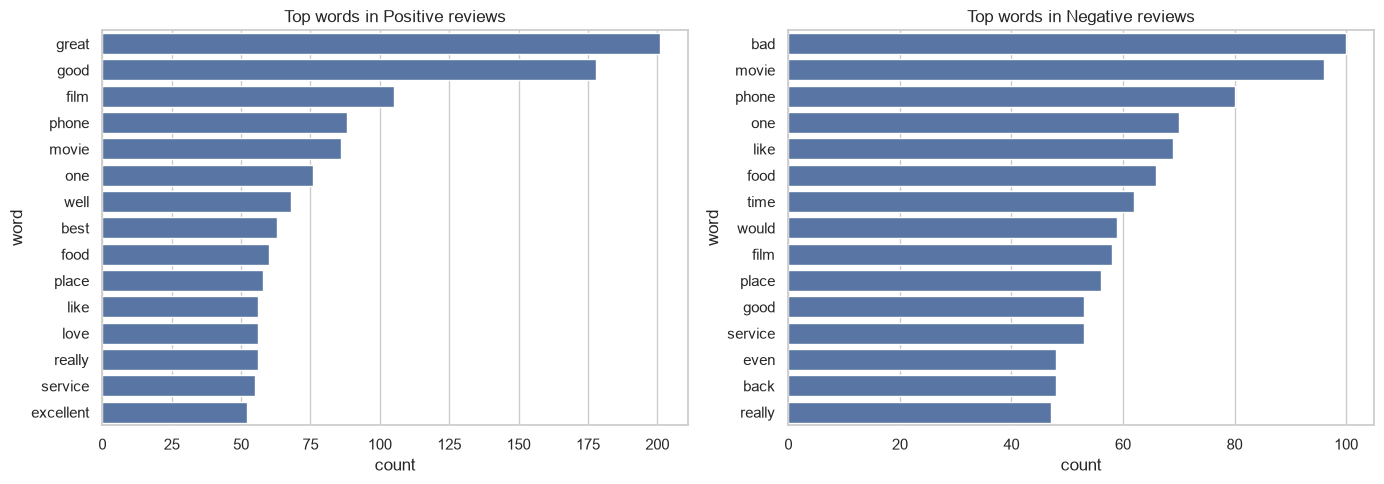

In [7]:
stop_words = set(stopwords.words("english"))

def top_words(label, n=15):
    words = " ".join(df[df["label"] == label]["clean_text"]).split()
    words = [w for w in words if w not in stop_words and len(w) > 2]
    return Counter(words).most_common(n)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, label, name in zip(axes, [1, 0], ["Positive", "Negative"]):
    data = pd.DataFrame(top_words(label), columns=["word", "count"])
    sns.barplot(data=data, x="count", y="word", ax=ax)
    ax.set_title(f"Top words in {name} reviews")
plt.tight_layout()
plt.show()

In [8]:
neg_good = df[(df["label"] == 0) & df["clean_text"].str.contains(r"\bgood\b")]
print("Negative reviews containing 'good':", len(neg_good))

negation = r"\b(not|no|never|isn|wasn|don|didn|doesn|wouldn|couldn|can|won)\b"
neg_good_negated = neg_good[neg_good["clean_text"].str.contains(negation)]
print("...of which also contain a negation word:", len(neg_good_negated))

neg_good_negated[["text"]].head(5)

Negative reviews containing 'good': 53
...of which also contain a negation word: 35


C:\Users\rajap\AppData\Local\Temp\ipykernel_5160\26114350.py:5: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  neg_good_negated = neg_good[neg_good["clean_text"].str.contains(negation)]


,text
81,Not a good bargain.
374,Not a good item.. It worked for a while then s...
455,Not good when wearing a hat or sunglasses.
563,If you are looking for a good quality Motorola...
637,"However, BT headsets are currently not good fo..."


### Observations

Positive reviews are led by clearly favourable words such as "great" (about 200 occurrences), "good", "best", "love", "well" and "excellent". Negative reviews are led by "bad" (about 100 occurrences), but beyond that the list is mostly neutral words such as "one", "time", "would", "even" and "back". Many frequent words ("movie", "film", "phone", "food", "place", "service", "like", "really") appear in both classes, because they describe the subject of a review and say nothing about sentiment. Notably, "good" also appears among the top negative words: of the 53 negative reviews containing "good", 35 also contain a negation word, and examples such as "Not a good bargain" show negation reversing the meaning. Because "not" is removed as a stop word in the chart above, raw word counts hide negation, which matters for sentiment. A few matches (for example, reviews with "can" or "no" that do not negate "good") show that this simple pattern slightly overcounts.

## 4. Split the dataset

In [9]:
X = df["clean_text"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train size:", len(X_train), "| Test size:", len(X_test))

Train size: 2400 | Test size: 600


## 5. Bag-of-Words representation

In [10]:
vectorizer = CountVectorizer(stop_words="english", min_df=2)
X_train_bow = vectorizer.fit_transform(X_train)   # fit on train only
X_test_bow = vectorizer.transform(X_test)

print("Vocabulary size:", len(vectorizer.vocabulary_))
print("Train matrix shape:", X_train_bow.shape)

Vocabulary size: 1649
Train matrix shape: (2400, 1649)


## 6. Train the models

In [11]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Linear SVM": LinearSVC(),
}

for name, model in models.items():
    model.fit(X_train_bow, y_train)
    print(f"{name} trained")

Logistic Regression trained
Linear SVM trained


## 7. Evaluate the models

In [12]:
results = []
predictions = {}

for name, model in models.items():
    pred = model.predict(X_test_bow)
    predictions[name] = pred
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
    })

results_df = pd.DataFrame(results).round(4)
results_df

,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.7983,0.7954,0.8033,0.7993
1,Linear SVM,0.7733,0.7562,0.8067,0.7806


===== Logistic Regression =====
              precision    recall  f1-score   support

    Negative       0.80      0.79      0.80       300
    Positive       0.80      0.80      0.80       300

    accuracy                           0.80       600
   macro avg       0.80      0.80      0.80       600
weighted avg       0.80      0.80      0.80       600

===== Linear SVM =====
              precision    recall  f1-score   support

    Negative       0.79      0.74      0.77       300
    Positive       0.76      0.81      0.78       300

    accuracy                           0.77       600
   macro avg       0.77      0.77      0.77       600
weighted avg       0.77      0.77      0.77       600



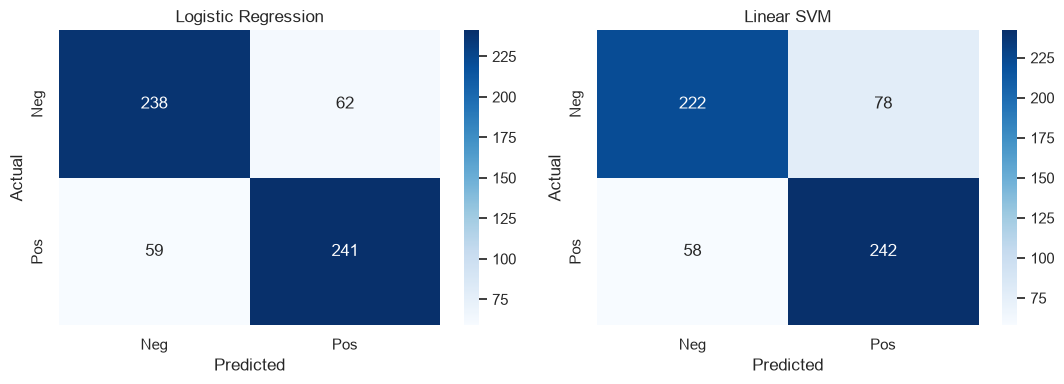

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, pred) in zip(axes, predictions.items()):
    print(f"===== {name} =====")
    print(classification_report(y_test, pred, target_names=["Negative", "Positive"]))
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["Neg", "Pos"], yticklabels=["Neg", "Pos"])
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

## 8. Test with new sentences

In [14]:
best_model = models["Logistic Regression"]

new_sentences = [
    "The battery life on this phone is fantastic",
    "The food was cold and the service was terrible",
    "I loved the plot and the acting in this movie",
    "It stopped working after two days, very disappointed",
    "The screen is not good in sunlight",
]

for s in new_sentences:
    vec = vectorizer.transform([clean_text(s)])
    label = best_model.predict(vec)[0]
    print(f"{'Positive' if label == 1 else 'Negative'}  <-  {s}")

Positive  <-  The battery life on this phone is fantastic
Negative  <-  The food was cold and the service was terrible
Positive  <-  I loved the plot and the acting in this movie
Negative  <-  It stopped working after two days, very disappointed
Positive  <-  The screen is not good in sunlight


### Observations

Logistic Regression performed slightly better overall, with an accuracy of 0.798 and an F1 score of 0.799, compared with 0.773 and 0.781 for the Linear SVM. The SVM had marginally higher recall (0.807 vs 0.803) but noticeably lower precision (0.756 vs 0.795), meaning it labelled more sentences as positive that were actually negative. With only 600 test sentences, the 2.5-point accuracy gap is about 15 sentences, so the difference may not be significant. Both models are limited by the Bag-of-Words representation, which ignores word order and, combined with stop-word removal, loses negation such as "not good". This showed up in the new-sentence test: four of the five sentences were classified correctly, but "The screen is not good in sunlight" was predicted as Positive, because the model saw the positive word "good" while "not" had been discarded as a stop word by the vectorizer.

## 9. Improving negation handling (extension)

The previous test showed that stop-word removal discards "not". Here the vectorizer keeps all words and adds two-word pairs (bigrams) so that phrases like "not good" become their own feature.

In [15]:
vec_ngram = CountVectorizer(ngram_range=(1, 2), min_df=2)   # keep "not", add word pairs
X_train_ng = vec_ngram.fit_transform(X_train)
X_test_ng = vec_ngram.transform(X_test)

model_ng = LogisticRegression(max_iter=1000).fit(X_train_ng, y_train)
print("Accuracy with bigrams and no stop-word removal:",
      round(accuracy_score(y_test, model_ng.predict(X_test_ng)), 4))

test_sentence = "The screen is not good in sunlight"
pred = model_ng.predict(vec_ngram.transform([clean_text(test_sentence)]))[0]
print("Prediction:", "Positive" if pred == 1 else "Negative", "<-", test_sentence)

Accuracy with bigrams and no stop-word removal: 0.8183
Prediction: Negative <- The screen is not good in sunlight


### Observations

Keeping all words and adding bigrams improved Logistic Regression accuracy on the test set from 0.798 to 0.818, an increase of 2 percentage points (about 12 of the 600 test sentences). The sentence "The screen is not good in sunlight", which was previously predicted as Positive, is now correctly predicted as Negative, which supports the hypothesis that discarding "not" as a stop word was harming the model. Two changes were made at once (stop words kept and bigrams added), so this experiment cannot show which one contributed more, and a single sentence and a single train/test split are not strong evidence on their own. A natural next step would be to test each change separately and use cross-validation to check that the improvement is consistent.

## 10. Save evidence images

This cell regenerates the key outputs from the variables above and saves them to the `screenshots` folder for the README.

In [16]:
import textwrap
from pathlib import Path

SHOTS = Path("../screenshots")
SHOTS.mkdir(exist_ok=True)

def save_text_image(text, filename, title=None, fontsize=10, width=12):
    """Render plain text (a table, printed output) as a PNG."""
    n_lines = text.count("\n") + 1
    fig, ax = plt.subplots(figsize=(width, 0.3 * n_lines + 1))
    ax.axis("off")
    if title:
        ax.set_title(title, loc="left", fontsize=12, fontweight="bold")
    ax.text(0, 1, text, family="monospace", fontsize=fontsize, va="top")
    fig.savefig(SHOTS / filename, dpi=150, bbox_inches="tight")
    plt.close(fig)

# 01 - dataset loaded
save_text_image(f"Shape: {df.shape}\n\n" + df.head().to_string(max_colwidth=60),
                "01-dataset-loaded.png", "Dataset loaded")

# 02 - label distribution
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="label", hue="source")
plt.title("Label distribution by source (0 = negative, 1 = positive)")
plt.savefig(SHOTS / "02-label-distribution.png", dpi=150, bbox_inches="tight")
plt.close()

# 03 - preprocessing comparison
lines = []
for i in df.sample(3, random_state=7).index:
    lines.append(textwrap.fill(f"ORIGINAL : {df.loc[i, 'text']}", 110, subsequent_indent="           "))
    lines.append(textwrap.fill(f"CLEANED  : {df.loc[i, 'clean_text']}", 110, subsequent_indent="           "))
    lines.append("-" * 60)
save_text_image("\n".join(lines), "03-preprocessing-comparison.png", "Original vs cleaned text")

# 04 - top words
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, label, name in zip(axes, [1, 0], ["Positive", "Negative"]):
    data = pd.DataFrame(top_words(label), columns=["word", "count"])
    sns.barplot(data=data, x="count", y="word", ax=ax)
    ax.set_title(f"Top words in {name} reviews")
plt.tight_layout()
fig.savefig(SHOTS / "04-top-words.png", dpi=150, bbox_inches="tight")
plt.close(fig)

# 05 - model results table
save_text_image(results_df.to_string(index=False), "05-model-results.png", "Model comparison (test set)")

# 06 - confusion matrices and classification reports
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["Neg", "Pos"], yticklabels=["Neg", "Pos"])
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
fig.savefig(SHOTS / "06-confusion-matrices.png", dpi=150, bbox_inches="tight")
plt.close(fig)

report_text = "\n\n".join(
    f"===== {n} =====\n" + classification_report(y_test, p, target_names=["Negative", "Positive"])
    for n, p in predictions.items()
)
save_text_image(report_text, "06b-classification-reports.png", "Classification reports")

# 07 - new sentence predictions
lines = []
for s in new_sentences:
    label = best_model.predict(vectorizer.transform([clean_text(s)]))[0]
    lines.append(f"{'Positive' if label == 1 else 'Negative'}  <-  {s}")
save_text_image("\n".join(lines), "07-new-sentence-predictions.png", "Predictions on new sentences")

# 08 - bigram improvement
acc_ng = accuracy_score(y_test, model_ng.predict(X_test_ng))
pred_ng = model_ng.predict(vec_ngram.transform([clean_text(test_sentence)]))[0]
save_text_image(
    f"Accuracy with bigrams and no stop-word removal: {acc_ng:.4f}\n"
    f"Prediction: {'Positive' if pred_ng == 1 else 'Negative'} <- {test_sentence}",
    "08-bigram-improvement.png", "Bigram extension")

print(sorted(p.name for p in SHOTS.iterdir()))

['01-dataset-loaded.png', '02-label-distribution.png', '03-preprocessing-comparison.png', '04-top-words.png', '05-model-results.png', '06-confusion-matrices.png', '06b-classification-reports.png', '07-new-sentence-predictions.png', '08-bigram-improvement.png']
